# Measuring importance among correlated predictors

Two identical predictors can each appear unimportant under one-at-a-time permutation because the untouched copy preserves the information:

$$
X_2=X_1
\quad\Longrightarrow\quad
\operatorname{MDA}_1\approx0,
\quad
\operatorname{MDA}_2\approx0
\quad\text{when either copy can replace the other.}
$$

Here, $X_1,X_2$ are identical predictors; $\Longrightarrow$ indicates the resulting substitution effect. $\operatorname{MDA}_1,\operatorname{MDA}_2$ are their separate permutation score decreases; $\approx0$ means close to zero in a fitted finite sample.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.ensemble import RandomForestClassifier

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.features.feature_importance import ClusteredFeatureImportanceMDA, ClusteredFeatureImportanceMDI, FeatureImportanceMDA, FeatureImportanceMDI, FeatureImportanceSFI, calculate_weighted_tau, conditional_predictive_impact, mdi_plus_importance, orthogonal_features

FIGURES = ROOT / "outputs" / "figures" / "14_feature_importance"
TABLES = ROOT / "outputs" / "tables" / "14_feature_importance"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

clusters = {
    "Consumer": ["Food", "Beer", "Hshld"],
    "Resources": ["Oil", "Coal", "Mines"],
    "Technology": ["Hardw", "Softw", "Chips"],
    "Finance": ["Banks", "Insur", "Fin"],
}
selected_features = [feature for values in clusters.values() for feature in values]
trailing_returns = industry_returns[selected_features].rolling(5).sum().shift(1)
market_direction = (industry_returns.mean(axis=1) > 0).astype(int).rename("Market direction")
public_frame = pd.concat([trailing_returns, market_direction], axis=1).dropna()
public_x = public_frame[selected_features]
public_y = public_frame["Market direction"]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def forest(seed, trees=120, depth=5, leaf=10, features=1):
    return RandomForestClassifier(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, max_features=features, random_state=seed, n_jobs=1, bootstrap=True)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Dependence Groups

,Cluster,Features,Mean within-cluster correlation
0,Consumer,"Food, Beer, Hshld",0.742331
1,Resources,"Oil, Coal, Mines",0.527364
2,Technology,"Hardw, Softw, Chips",0.760295
3,Finance,"Banks, Insur, Fin",0.756251


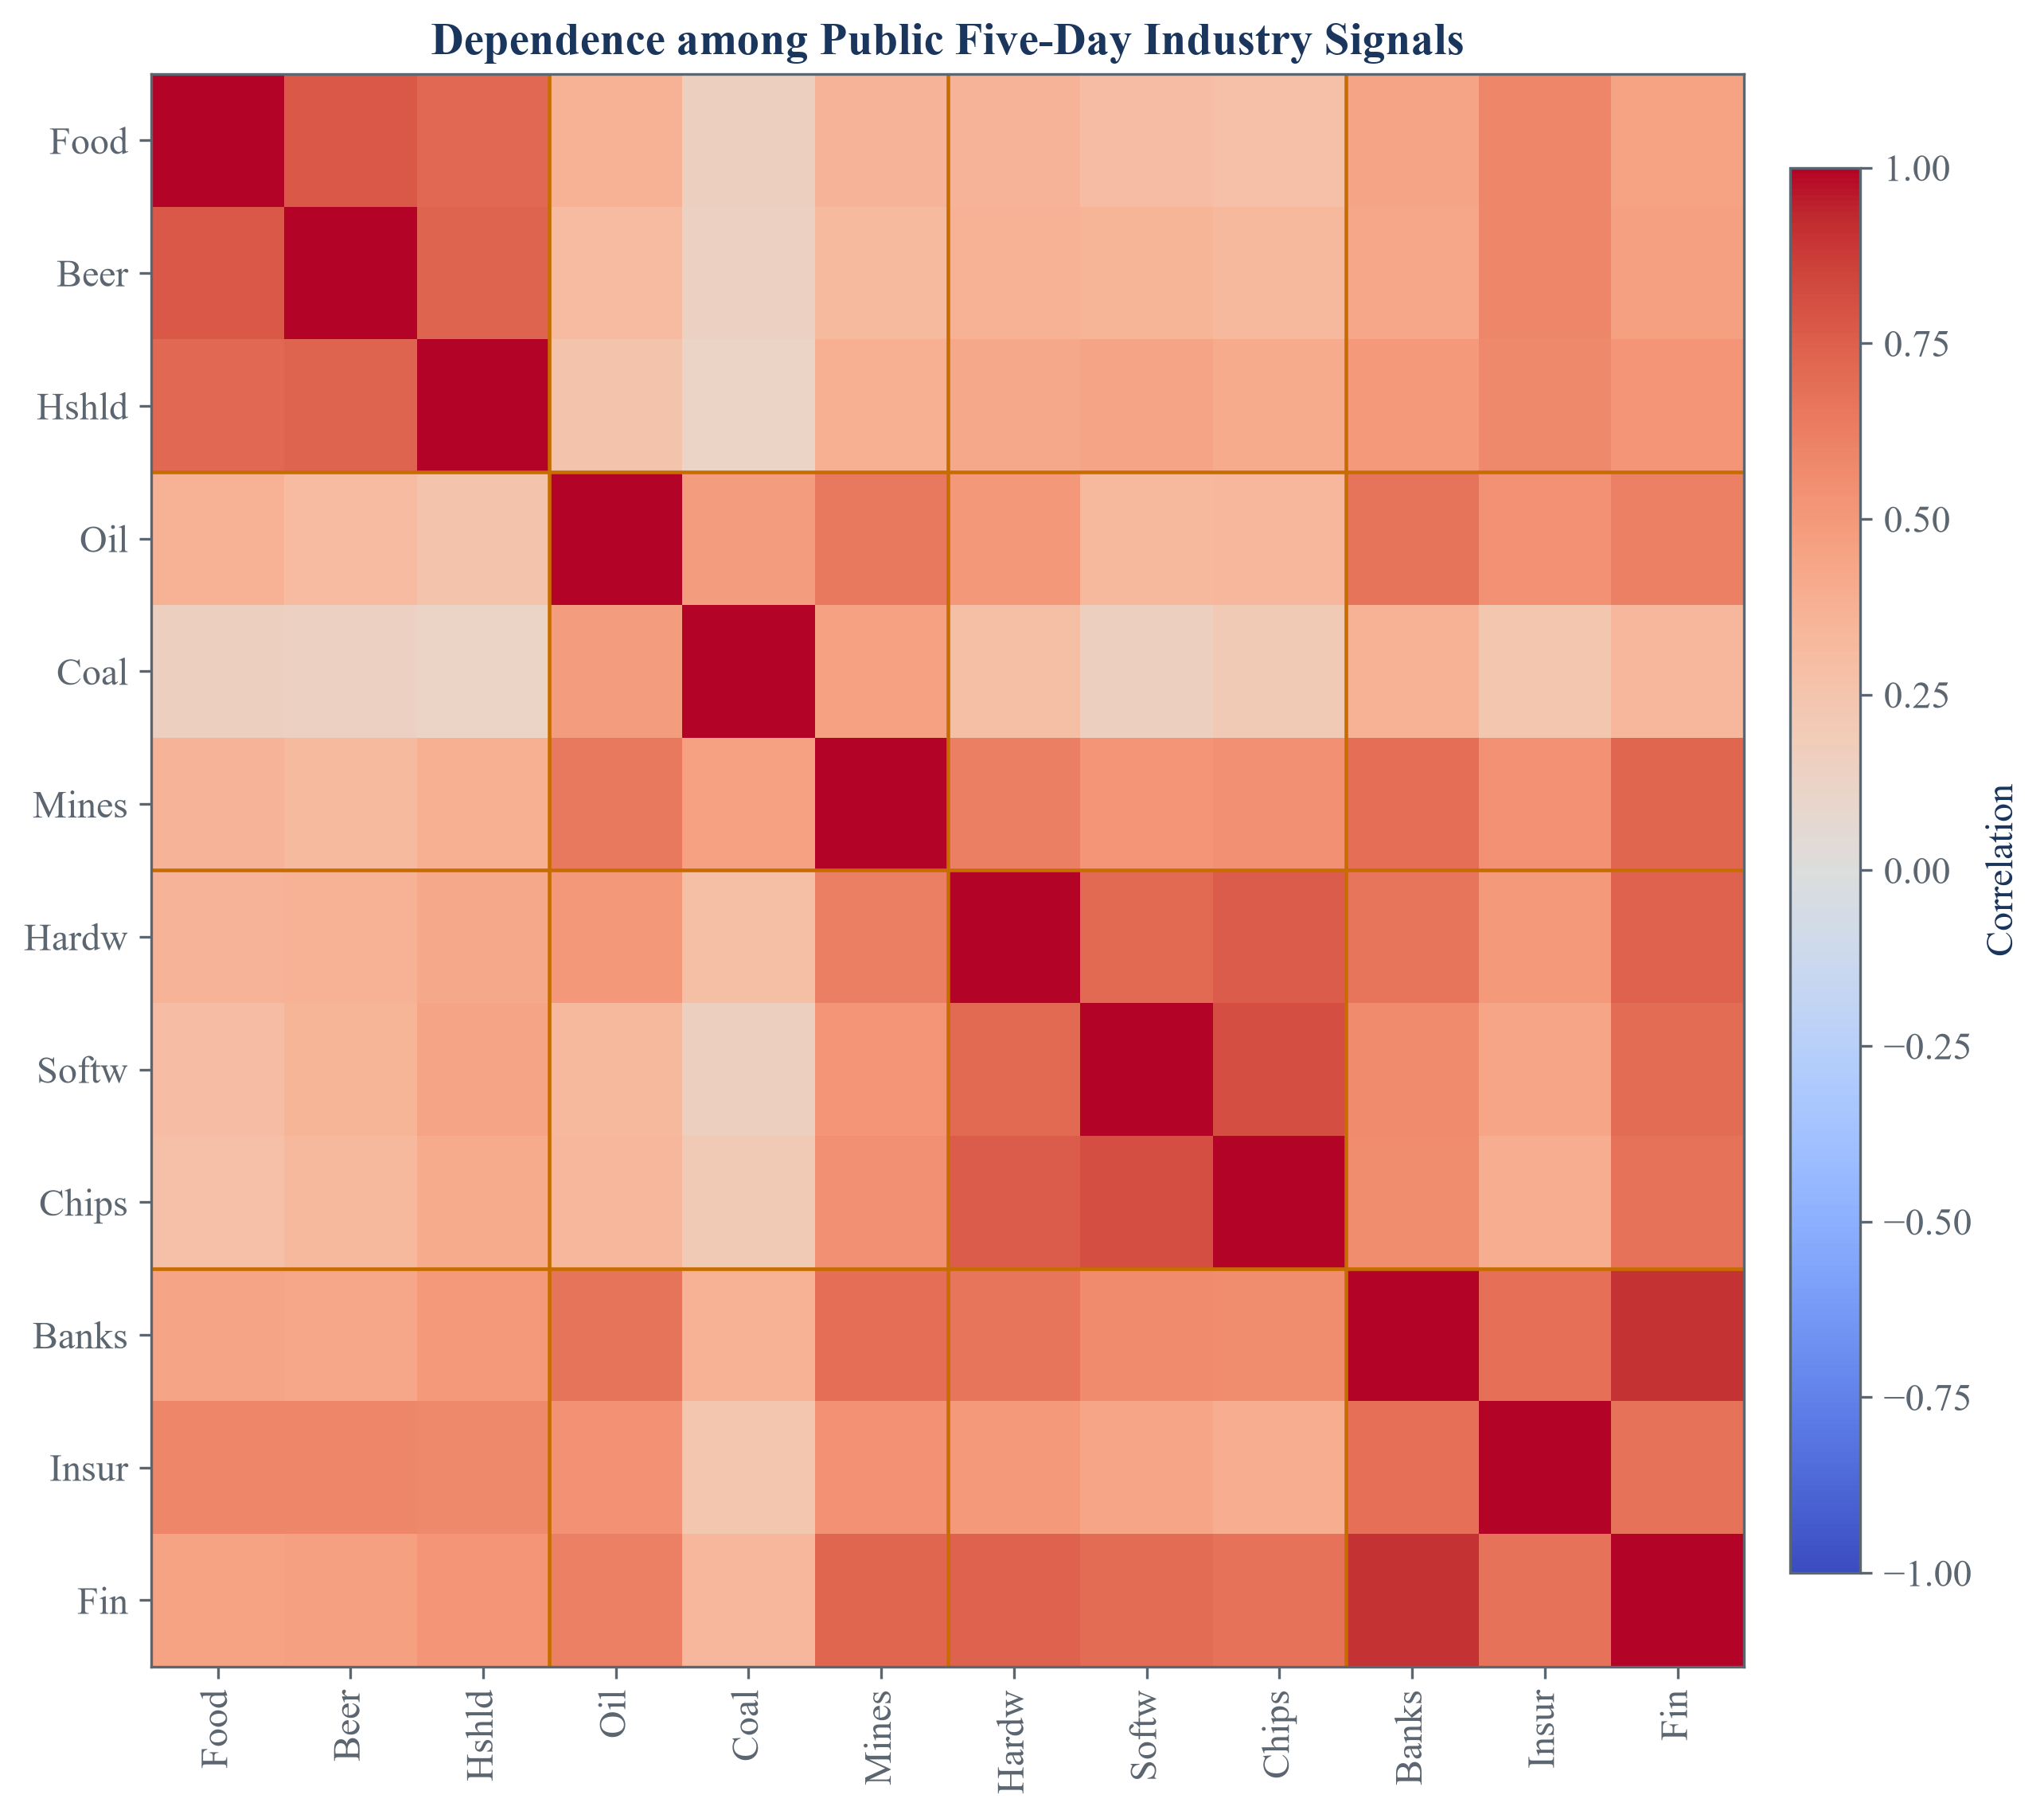

In [2]:
public_correlation = public_x.corr()
cluster_rows = []
for name, features in clusters.items():
    block = public_correlation.loc[features, features].to_numpy()
    within_values = block[np.triu_indices(len(features), 1)]
    cluster_rows.append({"Cluster": name, "Features": ", ".join(features), "Mean within-cluster correlation": within_values.mean()})
public_cluster_map = pd.DataFrame(cluster_rows)
save_table(public_cluster_map, "public_cluster_map", "Public industry groups and their within-group dependence.", "tab:chapter12-public-cluster-map", fit=True)
display(public_cluster_map.round(6))

figure, axis = plt.subplots(figsize=(9.0, 7.5), constrained_layout=True)
image = axis.imshow(public_correlation.to_numpy(), cmap="coolwarm", vmin=-1.0, vmax=1.0)
axis.set_xticks(np.arange(len(selected_features)), selected_features, rotation=90)
axis.set_yticks(np.arange(len(selected_features)), selected_features)
for boundary in [2.5, 5.5, 8.5]:
    axis.axhline(boundary, color=palette["amber"], linewidth=1.1)
    axis.axvline(boundary, color=palette["amber"], linewidth=1.1)
axis.set_title("Dependence among Public Five-Day Industry Signals")
figure.colorbar(image, ax=axis, fraction=0.038, pad=0.025, label="Correlation")
figure.savefig(FIGURES / "public_cluster_correlation.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_cluster_correlation.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_cluster_correlation.png")))
plt.close(figure)

## Comparing grouped importance estimates

Grouped MDI adds the split credit inside a group, while grouped MDA jointly reorders all features in that group:

$$
\operatorname{MDI}_{G}=\sum_{j\in G}\operatorname{MDI}_j,
\qquad
\operatorname{MDA}_{G}
=\frac{1}{K}\sum_{k=1}^{K}\left(S_k-S_{k,G}^{\pi}\right).
$$

Here, $G$ is a chosen feature group; $j\in G$ means feature $j$ belongs to it; $K$ is the number of folds. $S_k$ is the original held-out score; $S_{k,G}^{\pi}$ is the score after one common row permutation is applied to the columns in $G.$ $\operatorname{MDI}_{G}$ and $\operatorname{MDA}_{G}$ are the group-level impurity and predictive-score summaries.

,Cluster,Clustered MDI,Clustered MDA log-loss decrease
0,Consumer,0.270494,0.000126
1,Resources,0.24726,0.001636
2,Technology,0.227676,0.000282
3,Finance,0.25457,0.000876


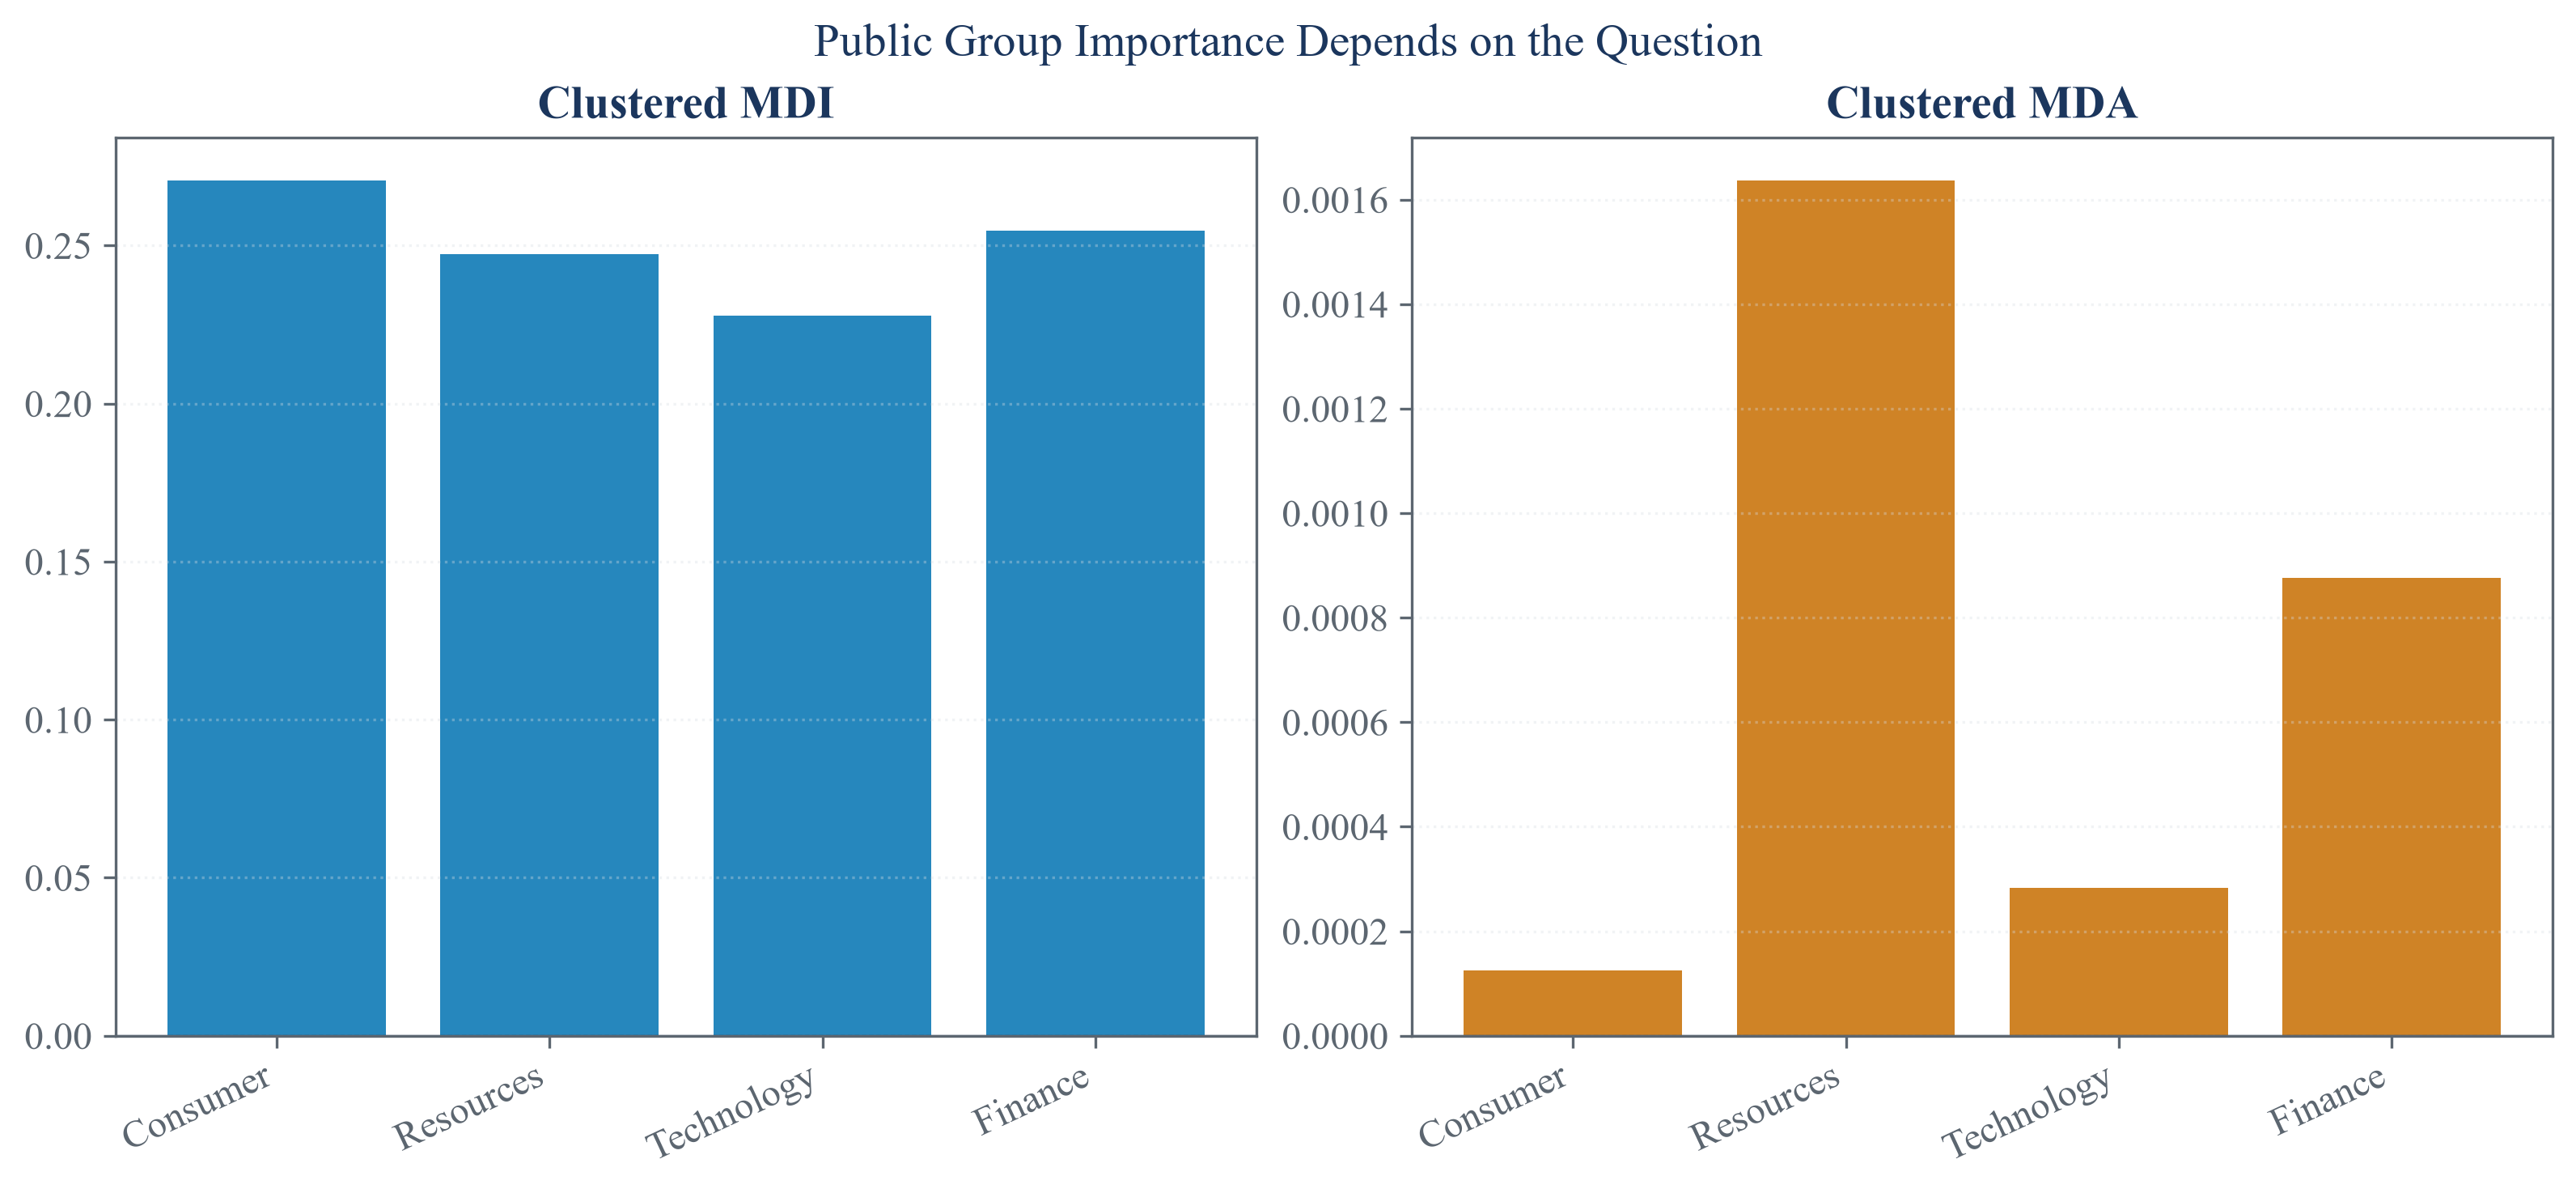

In [3]:
public_clustered_mdi = ClusteredFeatureImportanceMDI(forest(1231), clusters).compute(public_x, public_y)
public_clustered_mda = ClusteredFeatureImportanceMDA(forest(1232), clusters, n_splits=5, random_state=1233).compute(public_x, public_y)
public_cluster_importance = pd.concat([
    public_clustered_mdi["Mean"].rename("Clustered MDI"),
    public_clustered_mda["Mean"].rename("Clustered MDA log-loss decrease"),
], axis=1).reset_index(names="Cluster")
public_cluster_importance["Cluster"] = public_cluster_importance["Cluster"].str.removeprefix("C_")
save_table(public_cluster_importance, "public_cluster_importance", "Clustered importance on public industry signals.", "tab:chapter12-public-cluster-importance", fit=True)
display(public_cluster_importance.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), constrained_layout=True)
positions = np.arange(len(public_cluster_importance))
axes[0].bar(positions, public_cluster_importance["Clustered MDI"], color=palette["cyan"], alpha=0.85)
axes[1].bar(positions, public_cluster_importance["Clustered MDA log-loss decrease"], color=palette["amber"], alpha=0.85)
for axis, title in zip(axes, ["Clustered MDI", "Clustered MDA"]):
    axis.set_xticks(positions, public_cluster_importance["Cluster"], rotation=25, ha="right")
    axis.axhline(0, color=palette["text"], linewidth=0.8)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.35)
figure.suptitle("Public Group Importance Depends on the Question")
figure.savefig(FIGURES / "public_cluster_importance.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_cluster_importance.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_cluster_importance.png")))
plt.close(figure)

## A Fixed Information Set with More Copies

The experiment repeats exactly the same signal several times without adding any new information about the label:

$$
X_1=\cdots=X_q=Z,
\qquad
Y=\mathbf 1\!\left\{1.5Z+0.9\varepsilon>0\right\},
\qquad
q\in\{1,2,4,8\}.
$$

Here, $q$ is the number of identical signal columns; $X_1,\ldots,X_q$ are those columns; $Z$ is their shared standard-normal value. $Y$ is the binary label; $\varepsilon$ is an independent standard-normal shock; $1.5$ is signal strength; $0.9$ is label-noise scale.

,Signal copies,Largest individual MDI,Summed individual MDI,Clustered MDI,Largest individual MDA,Summed individual MDA,Clustered MDA
0,1,0.868704,0.868704,0.868293,1.872229,1.872229,1.772034
1,2,0.441545,0.869574,0.864623,0.174652,0.316566,1.656574
2,4,0.259171,0.875362,0.866288,0.041702,0.115611,1.404780
3,8,0.150124,0.902274,0.866530,0.035886,0.184669,1.520453


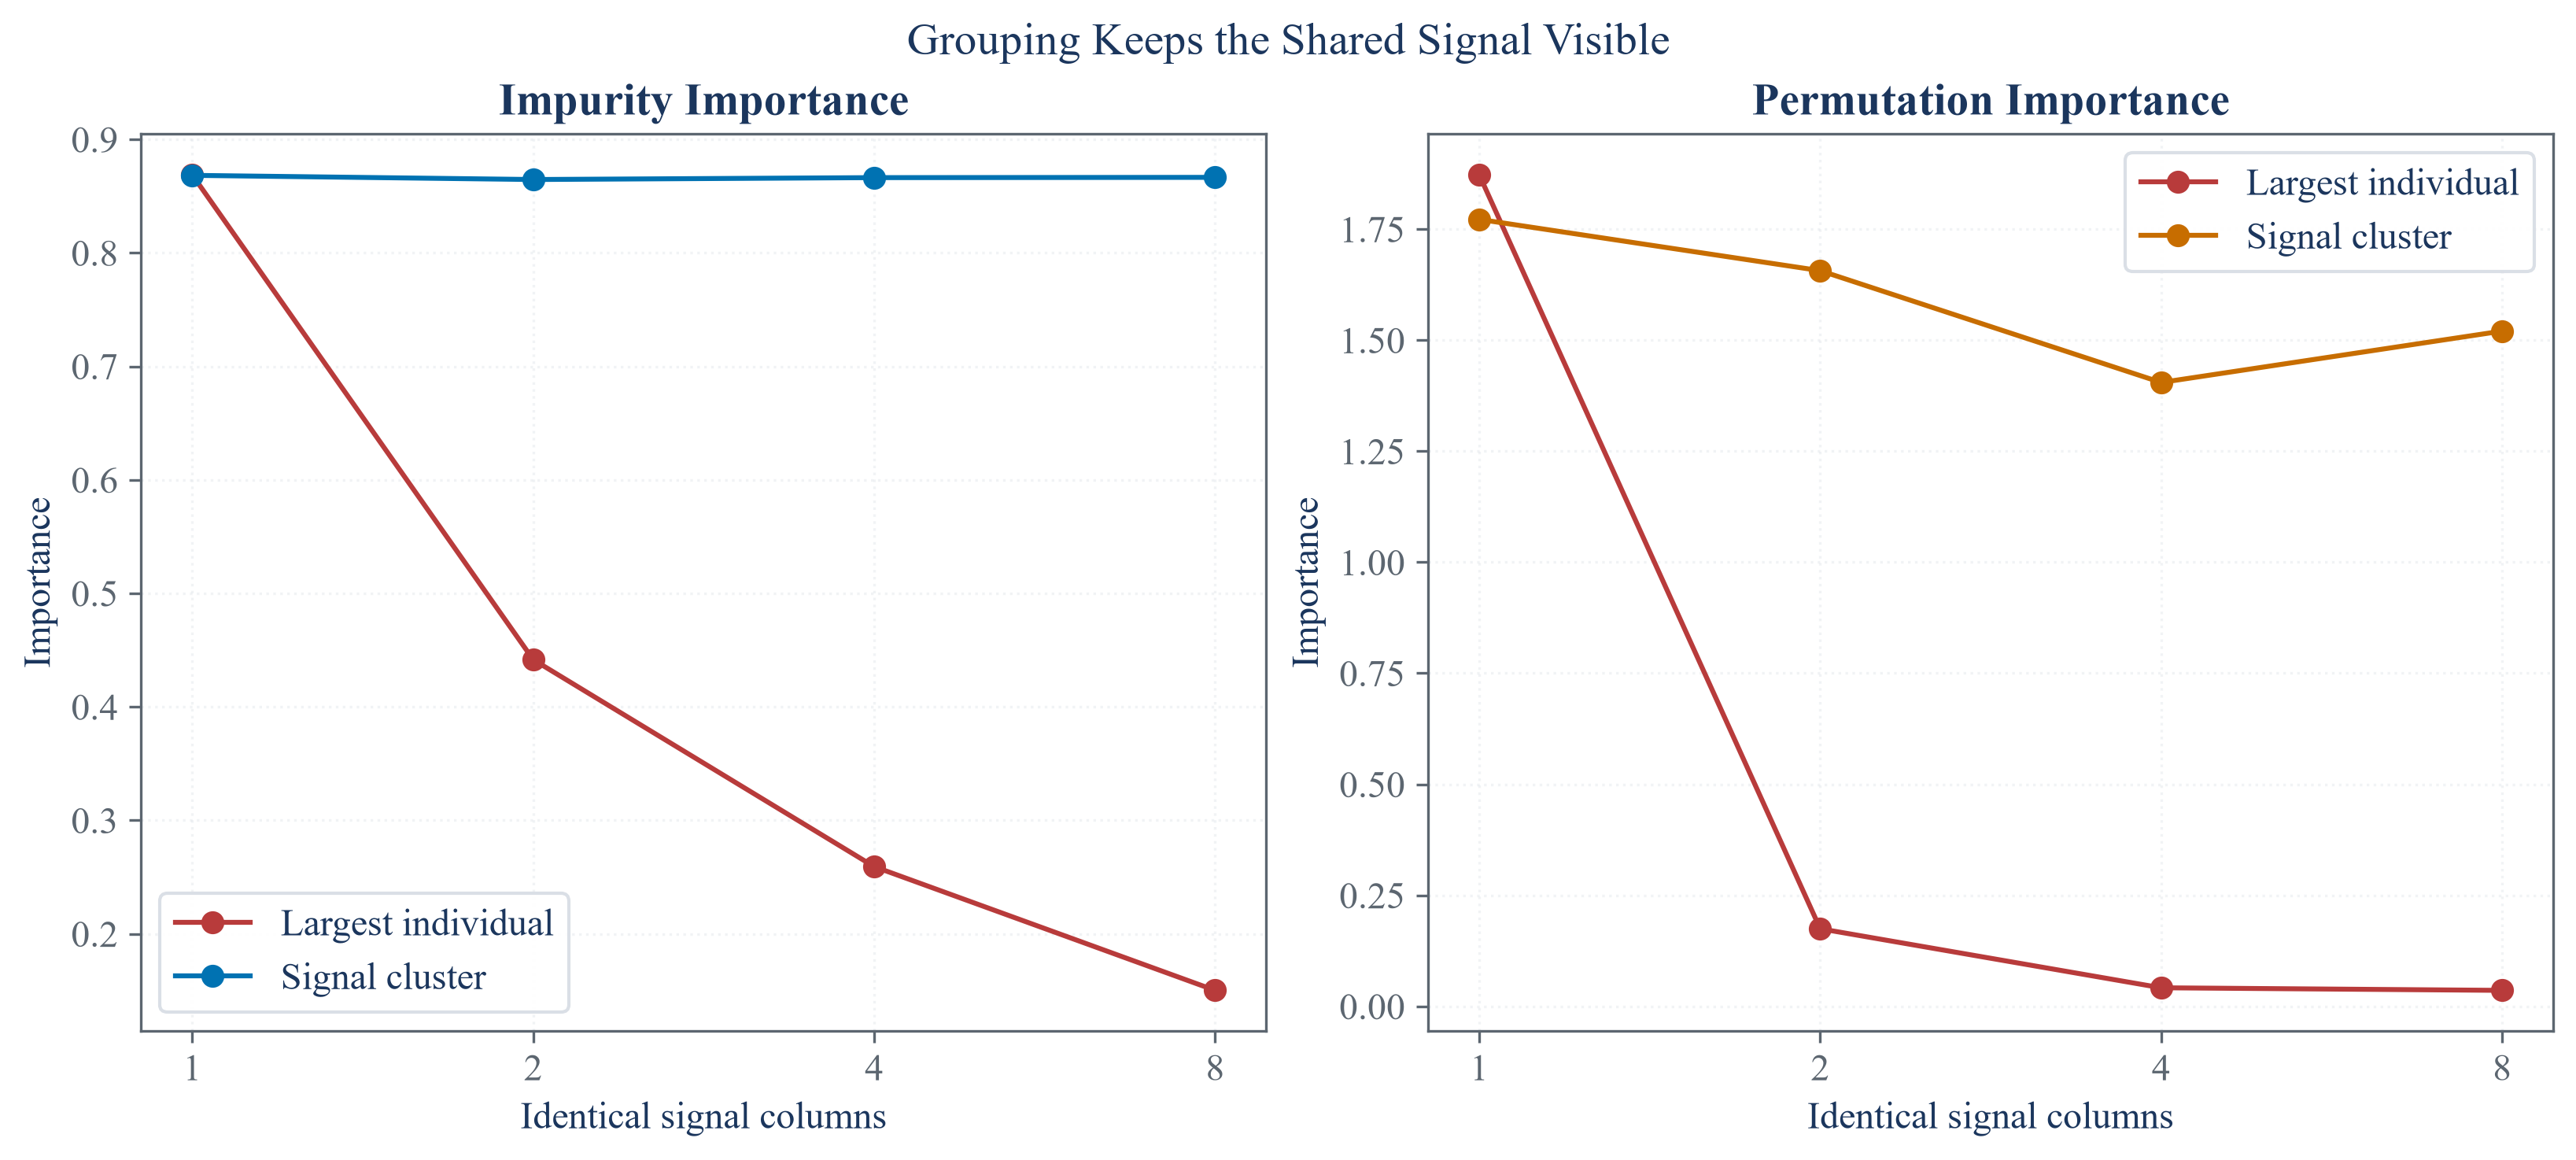

In [4]:
duplicate_rows = []
for duplicate_count in [1, 2, 4, 8]:
    duplicate_rng = np.random.default_rng(13000)
    observation_count = 1400
    latent_signal = duplicate_rng.normal(size=observation_count)
    duplicate_y = pd.Series((1.5 * latent_signal + 0.9 * duplicate_rng.normal(size=observation_count) > 0).astype(int))
    duplicate_data = {f"Signal {index + 1}": latent_signal for index in range(duplicate_count)}
    duplicate_data.update({f"Noise {index + 1}": duplicate_rng.normal(size=observation_count) for index in range(4)})
    duplicate_x = pd.DataFrame(duplicate_data)
    signal_names = [f"Signal {index + 1}" for index in range(duplicate_count)]
    noise_names = [f"Noise {index + 1}" for index in range(4)]
    duplicate_clusters = {"Signal": signal_names, "Noise": noise_names}
    full_feature_forest = lambda seed: RandomForestClassifier(n_estimators=120, max_depth=6, min_samples_leaf=8, max_features=None, random_state=seed, n_jobs=1, bootstrap=True)
    duplicate_mdi = FeatureImportanceMDI(full_feature_forest(13010 + duplicate_count)).compute(duplicate_x, duplicate_y)
    duplicate_mda = FeatureImportanceMDA(full_feature_forest(13020 + duplicate_count), n_splits=4, random_state=13030 + duplicate_count).compute(duplicate_x, duplicate_y)
    duplicate_clustered_mdi = ClusteredFeatureImportanceMDI(full_feature_forest(13040 + duplicate_count), duplicate_clusters).compute(duplicate_x, duplicate_y)
    duplicate_clustered_mda = ClusteredFeatureImportanceMDA(full_feature_forest(13050 + duplicate_count), duplicate_clusters, n_splits=4, random_state=13060 + duplicate_count).compute(duplicate_x, duplicate_y)
    duplicate_rows.append({
        "Signal copies": duplicate_count,
        "Largest individual MDI": duplicate_mdi.loc[signal_names, "Mean"].max(),
        "Summed individual MDI": duplicate_mdi.loc[signal_names, "Mean"].sum(),
        "Clustered MDI": duplicate_clustered_mdi.loc["C_Signal", "Mean"],
        "Largest individual MDA": duplicate_mda.loc[signal_names, "Mean"].max(),
        "Summed individual MDA": duplicate_mda.loc[signal_names, "Mean"].sum(),
        "Clustered MDA": duplicate_clustered_mda.loc["C_Signal", "Mean"],
    })
controlled_substitution = pd.DataFrame(duplicate_rows)
save_table(controlled_substitution, "controlled_substitution", "Identical-signal substitution as the number of copies grows.", "tab:chapter12-controlled-substitution", fit=True)
display(controlled_substitution.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.8), constrained_layout=True)
axes[0].plot(controlled_substitution["Signal copies"], controlled_substitution["Largest individual MDI"], marker="o", color=palette["rose"], label="Largest individual")
axes[0].plot(controlled_substitution["Signal copies"], controlled_substitution["Clustered MDI"], marker="o", color=palette["cyan"], label="Signal cluster")
axes[1].plot(controlled_substitution["Signal copies"], controlled_substitution["Largest individual MDA"], marker="o", color=palette["rose"], label="Largest individual")
axes[1].plot(controlled_substitution["Signal copies"], controlled_substitution["Clustered MDA"], marker="o", color=palette["amber"], label="Signal cluster")
for axis, title in zip(axes, ["Impurity Importance", "Permutation Importance"]):
    axis.set_xscale("log", base=2)
    axis.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
    axis.set_xlabel("Identical signal columns")
    axis.set_ylabel("Importance")
    axis.set_title(title)
    axis.grid(alpha=0.35)
    axis.legend()
figure.suptitle("Grouping Keeps the Shared Signal Visible")
figure.savefig(FIGURES / "controlled_substitution.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "controlled_substitution.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "controlled_substitution.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == EXPECTED_DATA_HASH
assert public_correlation.shape == (12, 12)
assert np.allclose(np.diag(public_correlation), 1.0)
assert np.allclose(public_correlation, public_correlation.T)
assert public_cluster_map.shape == (4, 3)
assert public_cluster_map["Mean within-cluster correlation"].min() > 0.45
assert set(feature for values in clusters.values() for feature in values) == set(selected_features)
assert public_clustered_mdi.shape == (4, 2)
assert np.isclose(public_clustered_mdi["Mean"].sum(), 1.0)
assert public_clustered_mda.shape == (4, 2)
assert public_cluster_importance.shape == (4, 3)
assert controlled_substitution.shape == (4, 7)
assert controlled_substitution["Signal copies"].tolist() == [1, 2, 4, 8]
assert controlled_substitution["Largest individual MDI"].iloc[-1] < controlled_substitution["Largest individual MDI"].iloc[0] / 4
assert controlled_substitution["Largest individual MDA"].iloc[-1] < controlled_substitution["Largest individual MDA"].iloc[0] / 10
assert controlled_substitution["Clustered MDI"].min() > 0.80
assert controlled_substitution.loc[controlled_substitution["Signal copies"] >= 2, "Clustered MDA"].min() > 1.0
assert controlled_substitution["Summed individual MDA"].iloc[-1] < controlled_substitution["Clustered MDA"].iloc[-1] / 5
assert (FIGURES / "public_cluster_correlation.pdf").is_file()
assert (FIGURES / "public_cluster_importance.pdf").is_file()
assert (FIGURES / "controlled_substitution.pdf").is_file()
assert (TABLES / "public_cluster_map.tex").is_file()
assert (TABLES / "public_cluster_importance.tex").is_file()
assert (TABLES / "controlled_substitution.tex").is_file()